# Cox Proportional Hazards Model

## Introduction

This notebook develops and evaluates the primary multivariable Cox proportional hazards (Cox PH) model for patients diagnosed with Stage III colon cancer.

The analysis uses the prepared SEER cohort and the established preprocessing and modeling functions defined in the project source code.

The primary objective is to estimate the association between selected baseline patient and disease characteristics and overall survival, while evaluating whether the assumptions required by the Cox proportional hazards model are reasonably satisfied.

This notebook focuses on model development, diagnostic evaluation, and interpretation of the final model.

## Model Objectives

The primary objectives of this analysis are:

1. Fit a multivariable Cox proportional hazards model using the predefined baseline covariates.
2. Estimate adjusted hazard ratios and their corresponding confidence intervals.
3. Evaluate the proportional hazards assumption for the overall model and individual covariates.
4. Assess the functional form of continuous predictors.
5. Investigate and address model assumption violations when statistically and clinically justified.
6. Evaluate the final model's performance and limitations.

Covariates are predefined based on the project's analytical objectives and clinical relevance rather than selected solely through univariate statistical significance.

## Load Data and Fit Model

The prepared analytical cohort is loaded using the project's existing data preparation function.

The multivariable Cox proportional hazards model is then fitted using the established modeling function. This function handles the model-specific preprocessing, constructs the design matrix, and fits the Cox model.

**Model specification:**

- Outcome: Overall survival
- Time variable: `Time` (months)
- Event indicator: `Event` (death = 1, right censored = 0)
- Model: Multivariable Cox proportional hazards
- Covariates: Predefined baseline patient and disease characteristics

The fitted model object will be used throughout the subsequent diagnostic and evaluation procedures.

In [8]:
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd().parent))

from src.models.models import preprocess_for_modeling, run_multivariable_model, preprocessing


In [9]:
df = preprocess_for_modeling()


Cleaned data loaded successfully.
Cleaned data shape: (14443, 36)
Recoded 99 -> NaN in: ['Regional nodes examined (1988+)', 'Regional nodes positive (1988+)', 'RX Summ--Surg Prim Site (1998-2022)']


In [10]:
df_cph = run_multivariable_model(df, duration_col='Time', event_col='Event')

## Model Results

The initial model results are examined to understand the estimated associations between the included covariates and overall survival.

The primary quantities of interest include:

- Regression coefficients (β)
- Hazard ratios (HR)
- 95% confidence intervals
- Statistical significance (p-values)

Hazard ratios greater than 1 indicate higher estimated hazard relative to the reference category, while hazard ratios below 1 indicate lower estimated hazard.

These estimates represent adjusted associations conditional on the other covariates included in the model.

Statistical significance will be interpreted alongside effect size, confidence intervals, and clinical context.

In [11]:
df_cph.print_summary()

<lifelines.CoxPHFitter: fitted with 14235 total observations, 7831 right-censored observations>
             duration col = 'Time'
                event col = 'Event'
      baseline estimation = breslow
   number of observations = 14235
number of events observed = 6404
   partial log-likelihood = -56240.07
         time fit was run = 2026-11-05 14:54:15 UTC

---
                                                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                                       
Age recode with single ages and 90+                             0.05      1.05      0.00            0.04            0.05                1.05                1.05
Sex                                                             0.18      1.19      0.03            0.13            0.23                1.13                1.26
Regional nodes examined (1988+)                                -0.01      0.99      0.00           -0.02           -0.01                0.98                0.99
Year of diagnosis                                              -0.01      0.99      0.00           -0.02           -0.01                0.98                0.99
Stage_IIIB                                                      0.61      1.85      0.05            0.51            0.72                1.66                2.05
Stage_IIIC                                                      1.38      3.99      0.06            1.27            1.49                3.57                4.46
Marital_Divorced                                               -0.03      0.97      0.05           -0.12            0.06                0.88                1.06
Marital_Married (including common law)                         -0.30      0.74      0.03           -0.36           -0.23                0.70                0.79
Marital_Separated                                              -0.02      0.98      0.15           -0.32            0.28                0.73                1.33
Marital_Unmarried or Domestic Partner                          -0.39      0.68      0.25           -0.88            0.11                0.42                1.11
Marital_Widowed                                                -0.05      0.95      0.04           -0.13            0.03                0.87                1.03
Race_Other (American Indian/AK Native, Asian/Pacific Islander) -0.25      0.78      0.05           -0.35           -0.15                0.71                0.86
Race_White                                                     -0.13      0.88      0.04           -0.21           -0.05                0.81                0.95

                                                                cmp to      z      p  -log2(p)
covariate                                                                                     
Age recode with single ages and 90+                               0.00  41.94 <0.005       inf
Sex                                                               0.00   6.70 <0.005     35.47
Regional nodes examined (1988+)                                   0.00 -10.69 <0.005     86.24
Year of diagnosis                                                 0.00  -3.63 <0.005     11.80
Stage_IIIB                                                        0.00  11.34 <0.005     96.54
Stage_IIIC                                                        0.00  24.64 <0.005    442.96
Marital_Divorced                                                  0.00  -0.64   0.52      0.94
Marital_Married (including common law)                            0.00  -9.00 <0.005     61.90
Marital_Separated                                                 0.00  -0.11   0.91      0.13
Marital_Unmarried or Domestic Partner                             0.00  -1.53   0.13      2.99
Marital_Widowed                                                   0.00  -1.24  

### Overall Model Performance

The initial multivariable Cox model demonstrated a concordance index of 0.72, indicating its ability to discriminate between patients with different survival outcomes.

The likelihood ratio test was statistically significant (χ² = 3750.99, df = 13), indicating that the included covariates collectively improved model fit compared with a null model.

The partial log-likelihood was -56,240.07, and the partial Akaike Information Criterion (AIC) was 112,506.14. These statistics provide measures of model fit and can be used for comparisons between appropriately specified Cox models.

Although the initial results demonstrate meaningful associations and discriminatory ability, they do not establish that the model adequately satisfies the proportional hazards assumption or other modeling requirements. Further diagnostic evaluation is necessary before drawing final conclusions.

In [12]:
# Extract overall model performance statistics

model_performance = pd.Series({
    "Observations": df_cph._n_examples,
    "Events": df_cph.event_observed.sum(),
    "Concordance Index": df_cph.concordance_index_,
    "Partial Log-Likelihood": df_cph.log_likelihood_,
    "Partial AIC": df_cph.AIC_partial_,
    "Likelihood Ratio Test": df_cph.log_likelihood_ratio_test().test_statistic,
    "Likelihood Ratio Test p-value": df_cph.log_likelihood_ratio_test().p_value
})

display(model_performance.to_frame("Value"))

,Value
Observations,14235.000000
Events,6404.000000
Concordance Index,0.719910
Partial Log-Likelihood,-56240.067711
Partial AIC,112506.135422
Likelihood Ratio Test,3750.985178
Likelihood Ratio Test p-value,0.000000


## Proportional Hazards Assumption

The Cox proportional hazards model assumes that hazard ratios remain constant over time.

This assumption will be evaluated using statistical tests and graphical diagnostics.

The analysis will examine:

- Global proportional hazards test.
- Covariate-specific proportional hazards tests.
- Schoenfeld residuals.
- Graphical patterns that may indicate time-dependent effects.

Potential violations will be investigated rather than interpreted solely from p-values. Particular attention will be given to the magnitude, consistency, and practical implications of any observed departures from proportional hazards.

In [21]:
# Reconstruct the complete-case dataset used by the Cox model

X = preprocessing(df)

cox_data = pd.concat(
    [
        df[["Time", "Event"]],
        X
    ],
    axis=1
).dropna()

print("Reconstructed dataset:", cox_data.shape)
print("Model observations:", df_cph._n_examples)
print("Missing values:", cox_data.isna().sum().sum())


Reconstructed dataset: (14235, 15)
Model observations: 14235
Missing values: 0


In [ ]:
# Test the proportional hazards assumption using the cox model's check_assumptions method

ph_results = df_cph.check_assumptions(
    cox_data,
    p_value_threshold=0.05,
    show_plots=False
)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'Age recode with single ages and 90+' failed the non-proportional test: p-value is 0.0003.

   Advice 1: the functional form of the variable 'Age recode with single ages and 90+' might be
incorrect. That is, there may be non-linear terms missing. The proportional hazard test used is very
sensitive to incorrect functional forms. See documentation in link [D] below on how to specify a
functional form.

   Advice 2: try binning the variable 'Age recode with single ages and 90+' using pd.cut, and then
specify it in `strata=['Age recode with single ages and 90+', ...]` in the call in `.fit`. See
documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'Regional nodes examined (1988+)' failed the non-proportional test: p-value is 0.0001.

   Advice 1: the functional form of the variable 'Regional nodes examined (1988+)' might be
incorrect. That is, there may be non-linear terms miss

### Statistical Assessment of the Proportional Hazards Assumption

The proportional hazards assumption was initially evaluated using the statistical tests provided by `lifelines` through `CoxPHFitter.check_assumptions()`.

These tests examine whether scaled Schoenfeld residuals are associated with survival time. Two time transformations were evaluated: Kaplan-Meier and rank.

A significance threshold of 0.05 was used to identify potential departures from proportional hazards.

The statistical assessment identified six predictors with significant test results under at least one transformation:

- Age
- Regional nodes examined
- Stage IIIB
- Stage IIIC
- Married
- Widowed

However, statistical significance alone does not establish the magnitude or practical importance of a proportional hazards violation. Given the sample size and the number of tests performed, relatively small departures may produce statistically significant results.

Consequently, the statistical tests were treated as an initial screening step rather than the sole basis for determining whether the proportional hazards assumption was adequately satisfied.

In [25]:
# Calculate scaled Schoenfeld residuals

schoenfeld_residuals = df_cph.compute_residuals(
    cox_data,
    kind="scaled_schoenfeld"
)

print("Residual dimensions:", schoenfeld_residuals.shape)
display(schoenfeld_residuals.head())

Residual dimensions: (6404, 13)


covariate,Age recode with single ages and 90+,Sex,Regional nodes examined (1988+),Year of diagnosis,Stage_IIIB,Stage_IIIC,Marital_Divorced,Marital_Married (including common law),Marital_Separated,Marital_Unmarried or Domestic Partner,Marital_Widowed,"Race_Other (American Indian/AK Native, Asian/Pacific Islander)",Race_White
13,-0.019016,-1.061473,-0.040288,-0.505668,1.570542,-0.421241,-0.423550,-0.111694,-0.320171,0.599240,3.921247,-0.285793,1.024291
59,0.079153,-2.322222,-0.199735,-0.571560,0.268359,3.307703,-4.587218,-3.487043,-5.202064,-1.585550,-6.155350,-8.827919,-9.032741
70,0.134470,1.872581,-0.048797,-0.537740,-0.190010,2.729519,0.125642,1.762205,0.652737,1.159888,-1.828824,-0.862186,0.130215
84,0.067827,1.803810,-0.080572,-0.537149,-0.049958,3.035892,0.495691,1.955816,0.599460,1.859741,-0.890839,6.781174,-0.880307
181,0.134973,-2.213777,-0.115643,-0.549087,1.535472,-0.148723,-4.951770,-4.899908,-4.143536,-2.532799,-7.989478,7.683727,0.286803


In [27]:
# Combine scaled Schoenfeld residuals with event times

plot_data = schoenfeld_residuals.join(
    cox_data[["Time"]],
    how="left"
)

print("Plot dataset shape:", plot_data.shape)
print("Missing event times:", plot_data["Time"].isna().sum())

Plot dataset shape: (6404, 14)
Missing event times: 0


### Visual Assessment of Potential Proportional Hazards Violations

To further investigate predictors flagged by the statistical tests, scaled Schoenfeld residuals were plotted against observed survival time.

LOWESS smoothing was applied to help identify systematic patterns in residuals over follow-up time.

Under the proportional hazards assumption, scaled Schoenfeld residuals should fluctuate around zero without exhibiting a systematic temporal trend. Consistent upward or downward patterns may indicate that the corresponding predictor's effect changes over time.

The visual assessment focused on the six predictors identified during statistical testing.

**Preliminary findings:**

- **Age:** A subtle nonlinear pattern was observed, with relatively small residual variation in the smoothed trend. The evidence of a meaningful proportional hazards violation is weak or ambiguous.
- **Regional nodes examined:** The smoothed trend remained relatively flat despite several extreme residual observations. Visual evidence of a meaningful violation is weak or ambiguous.
- **Stage IIIB:** The smoothed trend exhibited a gradual upward pattern over follow-up time, suggesting a potential time-dependent association.
- **Stage IIIC:** The smoothed trend showed an early upward pattern followed by a relatively stable trend. This was the strongest visual indication of potential time dependence.
- **Married:** The smoothed trend was relatively flat, with only a slight upward incline. Evidence of a meaningful violation is weak.
- **Widowed:** The smoothed trend remained approximately horizontal, with some extreme residual observations. No convincing visual evidence of a systematic temporal pattern was identified.

These findings are preliminary and should be interpreted alongside the statistical tests. Visual patterns alone do not establish the presence, magnitude, or clinical importance of a proportional hazards violation.

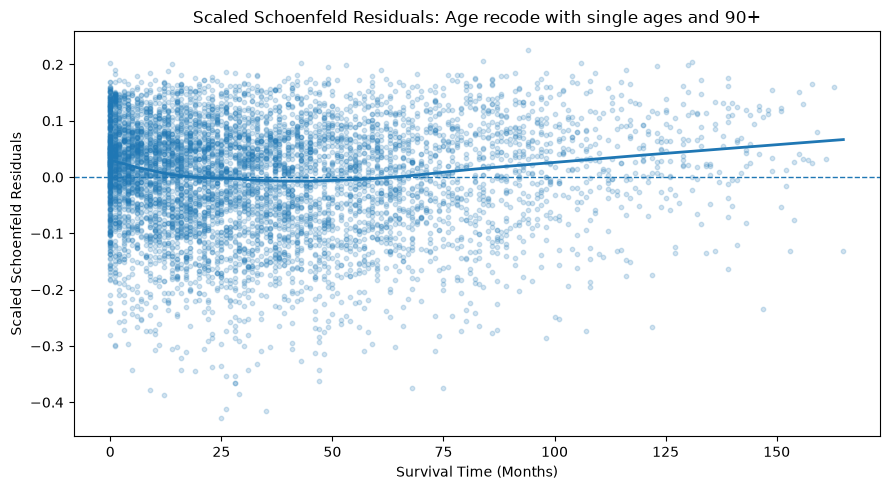

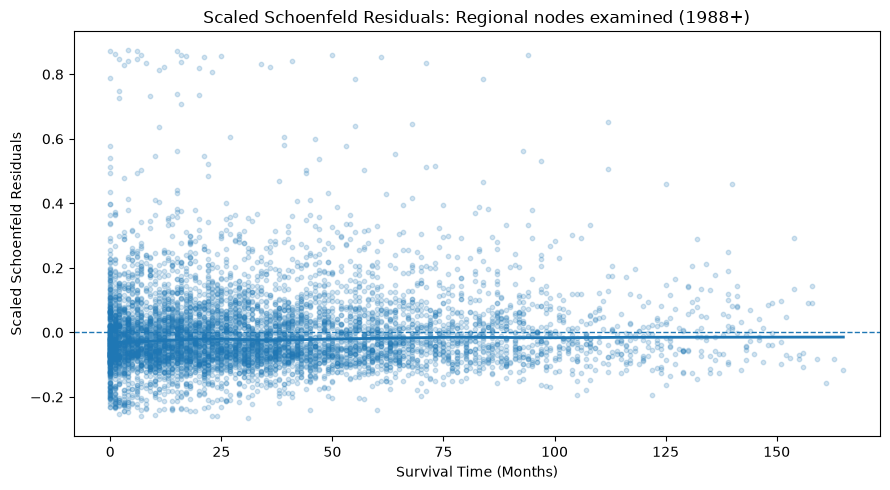

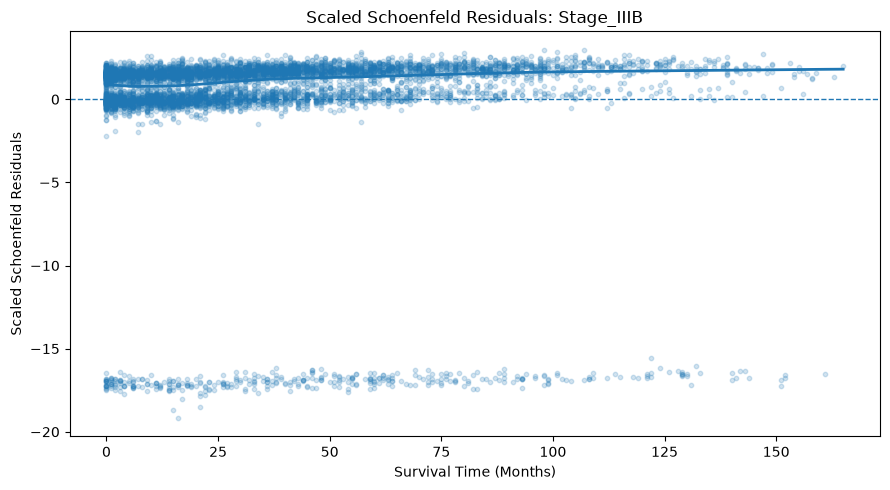

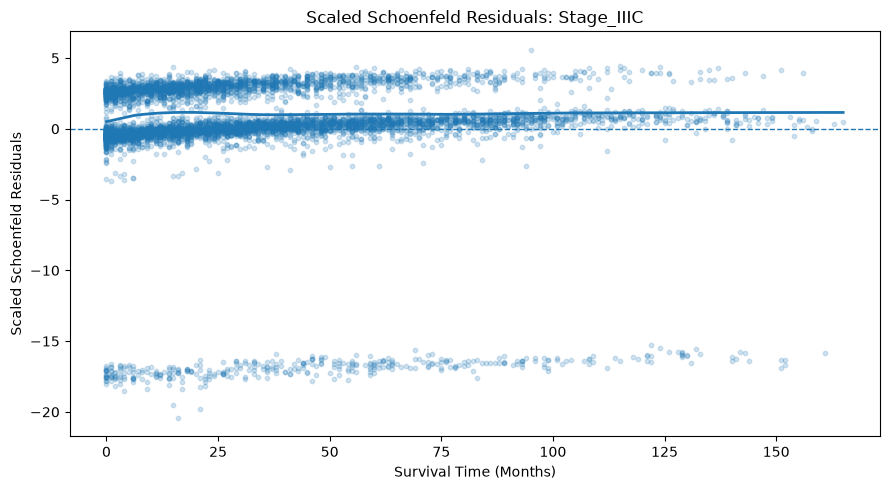

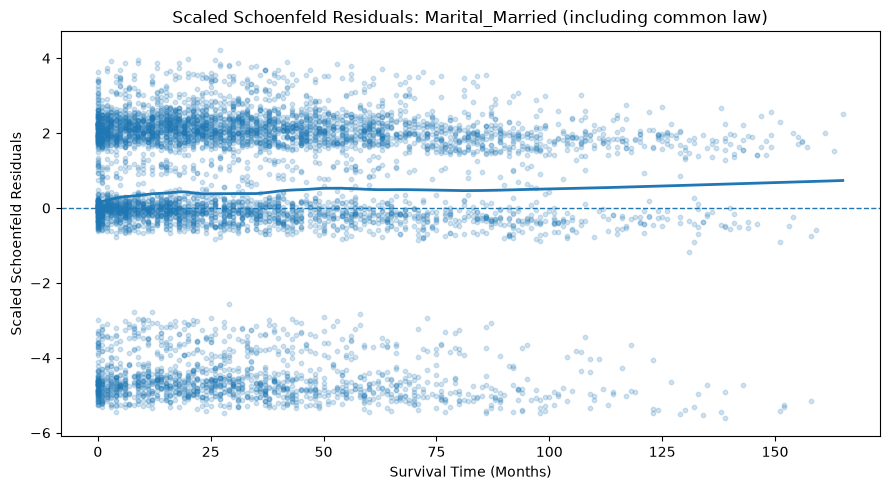

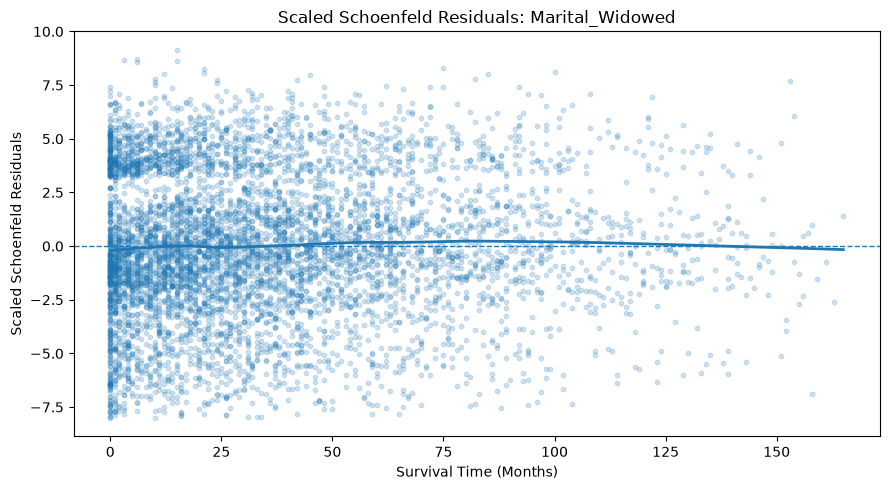

In [28]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Covariates flagged by the proportional hazards test
flagged_covariates = [
    "Age recode with single ages and 90+",
    "Regional nodes examined (1988+)",
    "Stage_IIIB",
    "Stage_IIIC",
    "Marital_Married (including common law)",
    "Marital_Widowed"
]

# Generate diagnostic plots
for covariate in flagged_covariates:

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.scatter(
        plot_data["Time"],
        plot_data[covariate],
        alpha=0.20,
        s=10
    )

    # LOWESS smoother without bootstrap confidence intervals
    lowess = sm.nonparametric.lowess(
        plot_data[covariate],
        plot_data["Time"],
        frac=0.30,
        return_sorted=True
    )

    ax.plot(
        lowess[:, 0],
        lowess[:, 1],
        linewidth=2
    )

    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(f"Scaled Schoenfeld Residuals: {covariate}")
    ax.set_xlabel("Survival Time (Months)")
    ax.set_ylabel("Scaled Schoenfeld Residuals")

    plt.tight_layout()
    plt.show()

## Functional Form of Continuous Predictors

The Cox proportional hazards model assumes that continuous predictors have an appropriate functional relationship with the log hazard.

In the current model, age, regional nodes examined, and year of diagnosis are entered as linear terms. This assumes that each one-unit increase in these predictors has a constant effect on the log hazard.

This section evaluates whether these linear specifications adequately represent their relationships with the log hazard.

The assessment will consider:

- Martingale residuals and graphical diagnostics.
- Potential nonlinear relationships between continuous predictors and the log hazard.
- Whether transformations or nonlinear terms, such as restricted cubic splines, may be justified.

Potential departures from linearity will be investigated before making changes to the model specification.

## Model Refinement

Findings from the proportional hazards and functional-form diagnostics will guide any necessary model refinement.

Potential approaches include:

- Stratification for covariates that violate the proportional hazards assumption, when appropriate.
- Time-varying coefficients for effects that change over time.
- Transformations or nonlinear terms for continuous predictors.
- Other justified modifications based on the observed diagnostic results.

Model modifications will be driven by statistical evidence, clinical reasoning, and interpretability.

The objective is not to maximize statistical significance or improve model fit at any cost, but to develop a defensible model that adequately represents the observed survival relationships.

All meaningful changes to the model specification will be documented.

## Final Model Evaluation

The final model will be evaluated after completing the diagnostic and refinement process.

Evaluation will consider:

- Whether the proportional hazards assumption is reasonably satisfied.
- Whether continuous predictors have appropriate functional forms.
- Model concordance and discrimination.
- Overall model fit and relevant performance measures.
- Stability and interpretability of the estimated effects.

The final evaluation will distinguish between model assumptions, statistical fit, and predictive performance. Satisfactory performance in one area does not necessarily establish adequacy in another.

## Final Model Interpretation and Limitations

This section summarizes the final Cox proportional hazards model and its principal findings.

The interpretation will include:

- Final model specification and included covariates.
- Adjusted hazard ratios and confidence intervals.
- Important findings from model diagnostics.
- Any modifications made during model refinement.
- Overall assessment of model adequacy.

### Limitations

Potential limitations include:

- Observational study design and the inability to establish causal relationships.
- Residual confounding from unmeasured or unavailable variables.
- Missing or incomplete information within the SEER dataset.
- Limitations associated with the selected covariates and their measurement.
- Generalizability of findings beyond the study population and period.

The final model will serve as the foundation for subsequent modeling approaches in the broader oncology survival simulation project.